# Right Stock, Right Place · Optimising IT Device Stock

The companion Power BI report (*Too Much Stock, Wrong Places*) checks a global IT device fleet (laptops, desktops, handhelds, tablets) against a **flat rule: keep spare stock equal to 10% of the devices in use** at every site.
It shows sites far above and far below that line. This notebook asks the next questions:

1. **What does each site actually need?** Spare devices are needed for three reasons: lifecycle refreshes, a backlog of devices already past their lifecycle, and break/fix or loss. Each is estimated from the data.
2. **Which sites should hold stock, and which should buy on demand?** An **ABC–XYZ** classification: ABC by fleet size, XYZ by how bursty the refresh demand is.
3. **What stock level is right?** Safety stock and reorder point per site and device type, compared with the 10% rule.
4. **How much can be moved instead of bought?** A **linear programme** that covers every site's shortfall at minimum cost, using surplus stock from other sites before buying new.

Sites are anonymised (`Brazil · site 03`). No person or asset names are loaded. The raw file is not included.

### Key Findings
* **Stock is 28% of the fleet, not 10%.** 17,591 devices sit in stock against 63,148 in use. A quarter of that stock (5,591) is reserved or already past its lifecycle, and **every one of the 750 handhelds in stock is unusable**.
* **The real need is much lower than the 10% rule.** From lifecycle refreshes, a backlog of 13,929 overdue devices and a 0.7% yearly break/fix rate, the sites need about **2,800 spare devices**, against 12,000 useful devices on hand and 7,047 under the 10% rule.
* **A flat percentage is wrong in both directions.** Because demand pools in large sites, **small sites (1–10 devices) need about 32% of their fleet as stock but hold 12%**, while **sites with 1,000+ devices need about 1% but hold 19%**.
* **Large sites refresh in predictable waves.** 76% of the fleet sits in large sites whose devices expire in batches (A–Z in the ABC–XYZ matrix). Those refreshes should be **bought as projects for the due month**, not kept on shelves.
* **Move before you buy.** A linear programme covers 1,024 of the 1,652 devices short by **moving surplus within the same country**, avoiding about **USD 1.0M** of purchases for USD 69K of transport. Even after that, **9,867 useful devices (≈ USD 10.4M)** are not needed anywhere: about 8 months of total demand.

In [ ]:
# ---- where things live -------------------------------------------------------------------------
import os, sys
from pathlib import Path
os.environ.setdefault("LOKY_MAX_CPU_COUNT", str(os.cpu_count() or 1))

MAIN_FOLDERS = [Path(r"C:\Users\Johanna\OneDrive\Documents\Portfolios\One Code")]
DATA_OVERRIDE = r""   # optional: full path of the raw asset workbook (.xlsx or .xlsb)

def code_folder():
    for p in [Path.cwd(), *Path.cwd().parents]:
        if (p / "octools.py").exists():
            return p
    for root in [*MAIN_FOLDERS, Path.cwd()]:
        if root.exists():
            hits = sorted(root.rglob("octools.py"), key=lambda f: len(f.parts))
            if hits:
                return hits[0].parent
    return None

CODE = code_folder()
if CODE is None:
    raise FileNotFoundError("octools.py not found. Keep it next to this notebook.")
os.chdir(CODE)
sys.path.insert(0, str(CODE))
import octools as oc

DATA = Path(DATA_OVERRIDE) if DATA_OVERRIDE else oc.find_workbook(
    [CODE / "data", CODE, CODE.parent / "data", CODE.parent, *MAIN_FOLDERS, *[m / "data" for m in MAIN_FOLDERS]])
if DATA is None or not DATA.exists():
    raise FileNotFoundError("Asset workbook not found. Put the .xlsx/.xlsb in the data folder, or paste its full path into DATA_OVERRIDE.")

IMAGES = next((p for p in [CODE / "images", CODE.parent / "images"] if p.exists()), CODE / "images")
IMAGES.mkdir(exist_ok=True)

def save(fig, name):
    fig.savefig(IMAGES / f"{name}.png", dpi=150, bbox_inches="tight", facecolor="white")

print("Code:", CODE.name, "| Data:", DATA.name, "| Images:", IMAGES.name)

import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from scipy.stats import norm
from scipy.optimize import linprog
from scipy.sparse import coo_matrix
from octools import NAVY, TEAL, TEAL_L, AMBER, CORAL, PLUM, SLATE, INK, MUTED, LINE

oc.style_charts()

Code: pkg | Data: Raw Data.xlsx | Images: images


## 1 · Load and Reconcile With the Dashboard

Same rules as the Power BI model. **In use** = Live or Lent Out. **Useful stock** = in stock and younger than lifecycle − 1 year (workstations 4 years, communication devices 3 years).
**Reserved** = in the last lifecycle year. **Being decomm** = past the lifecycle. Loading the full workbook takes a minute or two.

In [ ]:
a = oc.load(DATA)
AS_OF = a.as_of.iloc[0]
print(f"As of {AS_OF:%d %b %Y}: {len(a):,} devices in scope · {a.in_use.sum():,} in use · {a.in_stock.sum():,} in stock "
      f"· {a.country.nunique()} countries · {a.site.nunique()} sites")
recon = pd.crosstab(a[a.in_stock].asset_type, a[a.in_stock].usefulness, margins=True, margins_name="Total")
recon.insert(0, "in use", a[a.in_use].groupby("asset_type").size().reindex(recon.index[:-1]).tolist() + [a.in_use.sum()])
recon["stock % of in use"] = recon["Total"] / recon["in use"]
recon.style.format({"stock % of in use": "{:.0%}"}).format("{:,}", subset=[c for c in recon.columns if c != "stock % of in use"])

As of 19 Dec 2022: 192,627 devices in scope · 63,148 in use · 17,591 in stock · 91 countries · 893 sites


usefulness,in use,Being Decomm,Reserved,Useful,Total,stock % of in use
asset_type,,,,,,
Desktop,"13,221","1,785",334,"2,343","4,462",34%
Handheld,"1,392",745,5,0,750,54%
Laptop,"47,389","1,967",504,"9,475","11,946",25%
Monitor,12,0,0,2,2,17%
Tablet,"1,134",117,134,180,431,38%
Total,"63,148","4,614",977,"12,000","17,591",28%


**Reading the Table**
* The figures match the dashboard: **63,148 in use, 17,591 in stock (28%)**, of which 12,000 useful, 977 reserved and **4,614 being decommissioned**.
* **Handhelds are the extreme case:** 750 in stock, but none useful. 745 are past their lifecycle. On paper the stock is 54% of the handheld fleet; in practice it is zero.
* Desktops (34%) and tablets (38%) are the most overstocked by the 10% yardstick.

## 2 · Where Demand For Spare Devices Comes From

The 10% rule assumes every site needs spares in proportion to its fleet. In practice, spares are consumed for three reasons, and each can be measured:

* **Refresh**: in-use devices that reach the end of their lifecycle in the next 12 months.
* **Backlog**: in-use devices already *past* their lifecycle. They have to be replaced too; here they are spread over **24 months**.
* **Break/fix and loss**: devices broken down, being repaired or lost/stolen, per device-year of the last four years' fleet.

Monitors (14 devices) are left out: they are not stocked per site.

Break/fix + loss rate: 945 devices over 132,571 device-years = 0.71% per device per year
Refresh due in the next 12 months: 6,838 · in months 13–24: 10,944 · backlog already past lifecycle: 13,929 (22% of the fleet)


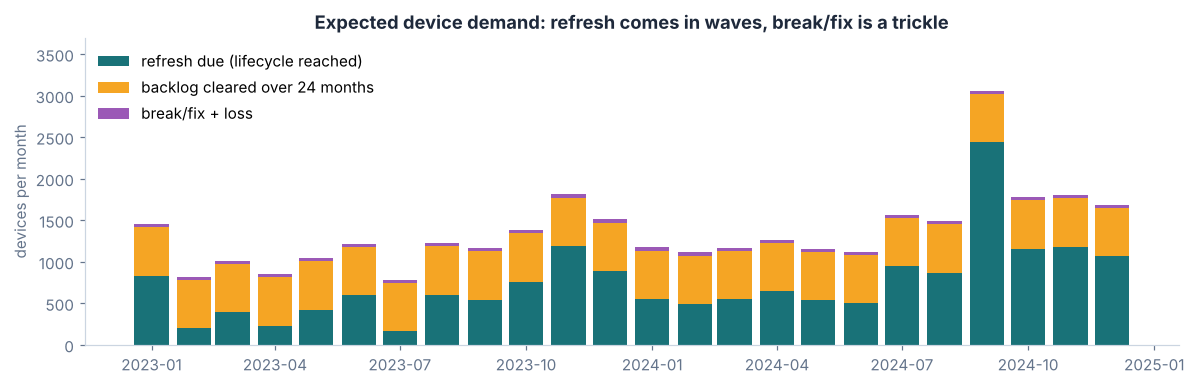

In [ ]:
TYPES = ["Laptop", "Desktop", "Handheld", "Tablet"]
a = a[a.asset_type.isin(TYPES)].copy()
a["months_to_refresh"] = (a.created + pd.to_timedelta(a.lifecycle_years * 365.25, unit="D") - AS_OF).dt.days / 30.44
fleet = a[a.in_use]

recent = a[a.created >= AS_OF - pd.DateOffset(years=4)]
failures = recent.status.isin(["Broken Down", "Being Repaired", "Lost or Stolen"]).sum()
device_years = ((AS_OF - recent.created).dt.days / 365.25).sum()
BREAKFIX_RATE = failures / device_years
BACKLOG_MONTHS = 24

due = fleet[(fleet.months_to_refresh >= 0) & (fleet.months_to_refresh < 24)]
monthly_due = due.groupby(np.floor(due.months_to_refresh).astype(int)).size().reindex(range(24)).fillna(0)
backlog = (fleet.months_to_refresh < 0).sum()
print(f"Break/fix + loss rate: {failures:,} devices over {device_years:,.0f} device-years = {BREAKFIX_RATE:.2%} per device per year")
print(f"Refresh due in the next 12 months: {(due.months_to_refresh < 12).sum():,} · in months 13–24: {(due.months_to_refresh >= 12).sum():,} "
      f"· backlog already past lifecycle: {backlog:,} ({backlog / len(fleet):.0%} of the fleet)")

fig, ax = plt.subplots(figsize=(11, 3.6))
months = pd.date_range(AS_OF + pd.offsets.MonthBegin(), periods=24, freq="MS")
ax.bar(months, monthly_due.values, width=25, color=TEAL, label="refresh due (lifecycle reached)")
ax.bar(months, [backlog / BACKLOG_MONTHS] * 24, width=25, bottom=monthly_due.values, color=AMBER, label=f"backlog cleared over {BACKLOG_MONTHS} months")
ax.bar(months, [len(fleet) * BREAKFIX_RATE / 12] * 24, width=25, bottom=monthly_due.values + backlog / BACKLOG_MONTHS, color=PLUM, label="break/fix + loss")
ax.set_ylabel("devices per month"); ax.legend(frameon=False, loc="upper left"); ax.set_ylim(0, ax.get_ylim()[1] * 1.15)
ax.set_title("Expected device demand: refresh comes in waves, break/fix is a trickle")
plt.tight_layout(); save(fig, "demand drivers"); plt.show()

**Reading the Demand**
* **Break/fix and loss are rare:** 945 devices over 132,571 device-years, or **0.71% of the fleet per year**. That is about 37 devices a month worldwide.
* **Refresh is the main driver.** 6,838 devices reach end of life in the next 12 months and 10,944 in the 12 after that. On top of that, **13,929 devices in use (22% of the fleet) are already past their lifecycle**.
* Together that is about **1,200 devices a month**, and it is **lumpy**: a single month (Sep 2024) needs about 3,000, because devices bought in one batch also expire in one batch. Lumpy, *known* demand is planned, not stocked.

## 3 · ABC–XYZ: Which Sites Should Hold Stock?

Each **site × device type** is classified twice:

* **ABC by fleet size**: A = the largest site-types that together hold 80% of the fleet, B = the next 15%, C = the last 5%.
* **XYZ by how bursty refresh demand is** over the next 24 months. The index of dispersion (variance ÷ mean of monthly refresh counts) is 1 for a steady, random trickle and much higher when devices were bought in one batch and all expire together.
  X = steady (≤ 1.5, or no refresh due), Y = uneven (1.5–4), Z = waves (> 4).

The policy that follows: **X and Y** refreshes are covered from stock. **Z** refreshes are known months in advance and should be **ordered as a project for the due month**, not kept on a shelf. Every site still keeps a buffer for break/fix and backlog.

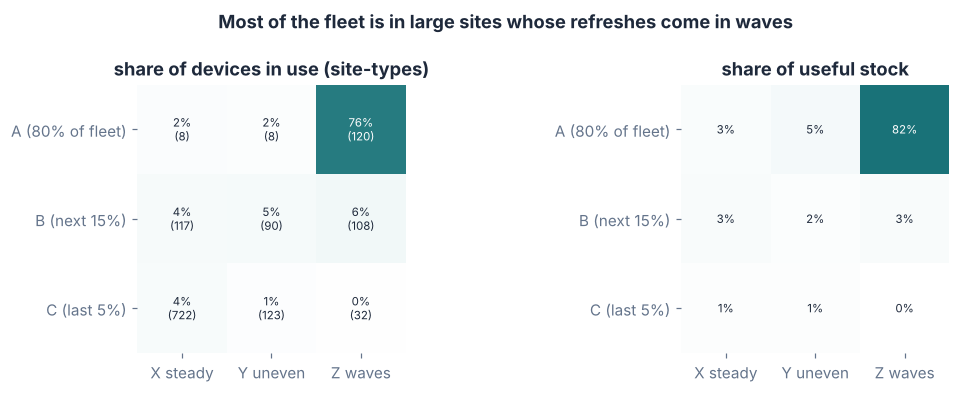

In [ ]:
KEY = ["country", "site_label", "asset_type"]
site_info = a.groupby(["country", "site_label"]).agg(city=("city", lambda c: c.mode().iat[0] if len(c.mode()) else "Unknown"), region=("region", "first"))
stock = a[a.in_stock]
g = pd.DataFrame({
    "in_use": fleet.groupby(KEY).size(),
    "due_12m": fleet[(fleet.months_to_refresh >= 0) & (fleet.months_to_refresh < 12)].groupby(KEY).size(),
    "backlog": fleet[fleet.months_to_refresh < 0].groupby(KEY).size(),
    "stock": stock.groupby(KEY).size(),
    "useful": stock[stock.usefulness == "Useful"].groupby(KEY).size(),
    "reserved": stock[stock.usefulness == "Reserved"].groupby(KEY).size(),
    "decomm": stock[stock.usefulness == "Being Decomm"].groupby(KEY).size()}).fillna(0).reset_index()
g = g.join(site_info, on=["country", "site_label"])

per_month = due.groupby(KEY + [np.floor(due.months_to_refresh).astype(int).rename("m")]).size().unstack("m").reindex(columns=range(24)).fillna(0)
dispersion = (per_month.var(axis=1) / per_month.mean(axis=1)).rename("dispersion").reset_index()
g = g.merge(dispersion, on=KEY, how="left")
g["XYZ"] = np.where(g.dispersion.isna() | (g.dispersion <= 1.5), "X", np.where(g.dispersion <= 4, "Y", "Z"))
g = g.sort_values("in_use", ascending=False).reset_index(drop=True)
share = g.in_use.cumsum() / g.in_use.sum()
g["ABC"] = np.where(share <= 0.80, "A", np.where(share <= 0.95, "B", "C"))
g.loc[g.in_use == 0, "ABC"] = "C"

counts = pd.crosstab(g.ABC, g.XYZ)
fleet_share = pd.crosstab(g.ABC, g.XYZ, values=g.in_use, aggfunc="sum").fillna(0) / g.in_use.sum()
stock_share = pd.crosstab(g.ABC, g.XYZ, values=g.useful, aggfunc="sum").fillna(0) / g.useful.sum()

from matplotlib.colors import LinearSegmentedColormap
CMAP = LinearSegmentedColormap.from_list("teal", ["#FFFFFF", TEAL_L, TEAL])
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.6))
for ax, m, title in [(axes[0], fleet_share, "share of devices in use (site-types)"), (axes[1], stock_share, "share of useful stock")]:
    ax.imshow(m.values, cmap=CMAP, vmin=0, vmax=0.8)
    for i in range(m.shape[0]):
        for j in range(m.shape[1]):
            v = m.values[i, j]
            ax.text(j, i, f"{v:.0%}\n({counts.values[i, j]:,})" if ax is axes[0] else f"{v:.0%}", ha="center", va="center",
                    fontsize=7.5, color="white" if v > 0.4 else INK)
    ax.set_xticks(range(m.shape[1])); ax.set_xticklabels(["X steady", "Y uneven", "Z waves"])
    ax.set_yticks(range(m.shape[0])); ax.set_yticklabels(["A (80% of fleet)", "B (next 15%)", "C (last 5%)"])
    ax.spines[:].set_visible(False); ax.set_title(title)
fig.suptitle("Most of the fleet is in large sites whose refreshes come in waves", fontweight="bold", color=INK)
plt.tight_layout(); save(fig, "abc xyz"); plt.show()
cls = g.groupby(["ABC", "XYZ"]).agg(site_types=("in_use", "size"), in_use=("in_use", "sum"), useful_stock=("useful", "sum"), refresh_12m=("due_12m", "sum"))
cls["useful % of fleet"] = cls.useful_stock / cls.in_use
cls.style.format({"site_types": "{:,}", "in_use": "{:,.0f}", "useful_stock": "{:,.0f}", "refresh_12m": "{:,.0f}", "useful % of fleet": "{:.0%}"})

**Reading the Matrix**
* **A–Z dominates:** 120 large site-types hold **76% of the fleet and 82% of the useful stock** (9,780 devices, 20% of their fleet). Their 5,305 refreshes in the next 12 months come in waves that can be seen years ahead. These are the sites where stock can come down most.
* **C–X is the long tail:** 722 small site-types (4% of the fleet, mostly a handful of devices each) with steady, small demand. They need a small buffer, or a nearby hub to draw from.
* **Policy by class:** A–Z / B–Z → order refreshes as projects timed to the due date and keep only a break/fix buffer. X / Y → keep a stock buffer that covers lead-time demand. C → serve from the nearest larger site where possible.

## 4 · The Right Stock Level per Site

For every site × device type:

* Monthly demand that stock must cover: **μ = refresh (only for X and Y) + backlog ÷ 24 + fleet × break/fix rate**, per month.
* **Lead time L = 1.5 months** to get a new device delivered and imaged (an assumption; see the sensitivity table).
* Demand during the lead time is treated as Poisson, so **safety stock = z × √(μ × L)**. The service level depends on the class: **A 95%, B 90%, C 85%**.
* **Target stock = μ × L + safety stock**, rounded up. It is compared with the useful stock on hand and with the 10% rule.

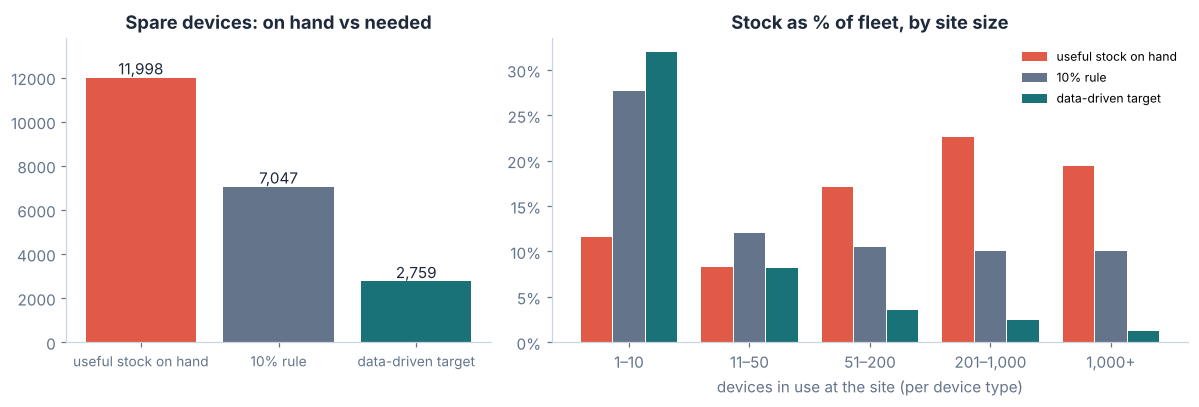

,site_types,in_use,useful,rule,target,useful %,rule %,target %
in_use,,,,,,,,
1–10,802,"2,900",335,802,926,12%,28%,32%
11–50,297,"7,150",595,860,586,8%,12%,8%
51–200,96,"9,283","1,589",971,332,17%,10%,4%
"201–1,000",73,"29,886","6,756","3,019",741,23%,10%,2%
"1,000+",8,"13,917","2,703","1,395",174,19%,10%,1%


In [ ]:
LEAD_MONTHS = 1.5
SERVICE = {"A": 0.95, "B": 0.90, "C": 0.85}

def targets(g, lead=LEAD_MONTHS, service=SERVICE, project_buy_z=True):
    refresh = g.due_12m / 12
    if project_buy_z:
        refresh = np.where(g.XYZ == "Z", 0, refresh)
    mu = refresh + g.backlog / BACKLOG_MONTHS + g.in_use * BREAKFIX_RATE / 12
    z = g.ABC.map({k: norm.ppf(v) for k, v in service.items()})
    t = np.ceil(mu * lead + z * np.sqrt(mu * lead))
    return pd.Series(np.where(g.in_use > 0, t, 0), index=g.index)

g["target"] = targets(g)
g["rule_10pct"] = np.ceil(g.in_use * 0.10 - 1e-9)

tot = pd.Series({"useful stock on hand": g.useful.sum(), "10% rule": g.rule_10pct.sum(), "data-driven target": g.target.sum()})
size_band = pd.cut(g.in_use, [0, 10, 50, 200, 1000, np.inf], labels=["1–10", "11–50", "51–200", "201–1,000", "1,000+"])
band = g[g.in_use > 0].groupby(size_band).agg(site_types=("in_use", "size"), in_use=("in_use", "sum"), useful=("useful", "sum"),
                                              rule=("rule_10pct", "sum"), target=("target", "sum"))
for c in ["useful", "rule", "target"]:
    band[c + " %"] = band[c] / band.in_use

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [1, 1.5]})
ax = axes[0]
ax.bar(tot.index, tot.values, color=[CORAL, SLATE, TEAL])
for i, v in enumerate(tot.values):
    ax.text(i, v + 150, f"{v:,.0f}", ha="center", fontsize=10, color=INK)
ax.set_title("Spare devices: on hand vs needed"); ax.set_ylim(0, tot.max() * 1.15); ax.tick_params(axis="x", labelsize=9)
ax = axes[1]
x = np.arange(len(band))
ax.bar(x - 0.27, band["useful %"], width=0.26, color=CORAL, label="useful stock on hand")
ax.bar(x, band["rule %"], width=0.26, color=SLATE, label="10% rule")
ax.bar(x + 0.27, band["target %"], width=0.26, color=TEAL, label="data-driven target")
ax.set_xticks(x); ax.set_xticklabels(band.index.astype(str)); ax.set_xlabel("devices in use at the site (per device type)")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}")); ax.legend(frameon=False, fontsize=8)
ax.set_title("Stock as % of fleet, by site size")
plt.tight_layout(); save(fig, "targets vs rule"); plt.show()

band.style.format({"site_types": "{:,}", "in_use": "{:,.0f}", "useful": "{:,.0f}", "rule": "{:,.0f}", "target": "{:,.0f}",
                   "useful %": "{:.0%}", "rule %": "{:.0%}", "target %": "{:.0%}"})

**Reading the Targets**
* **Total need: about 2,800 devices**, against 12,000 useful on hand and 7,047 under the 10% rule.
* **The square-root effect:** safety stock grows with the square root of demand, not in proportion to it. That is why the right stock is **32% of the fleet for sites with 1–10 devices** but **1–4% for sites with more than 50**. The 10% rule overstocks big sites and understocks tiny ones.
* Today the pattern is the reverse of what is needed: **small sites hold 12%** (short by about 600 devices in total), while **sites with 200+ devices hold 19–23%**.

### 4.1 How Sensitive Is the Target to the Assumptions?

In [ ]:
rows = []
for lead in (1.0, 1.5, 3.0):
    for name, svc in [("A95 / B90 / C85", SERVICE), ("99% everywhere", {"A": 0.99, "B": 0.99, "C": 0.99})]:
        for proj in (True, False):
            t = targets(g, lead, svc, proj)
            rows.append((f"{lead:g} months", name, "project-buy Z waves" if proj else "stock every refresh", t.sum(), g.useful.sum() - t.sum()))
sens = pd.DataFrame(rows, columns=["lead time", "service level", "refresh policy", "target devices", "useful stock above target"])
sens.style.hide(axis="index").format({"target devices": "{:,.0f}", "useful stock above target": "{:,.0f}"})

lead time,service level,refresh policy,target devices,useful stock above target
1 months,A95 / B90 / C85,project-buy Z waves,"2,265","9,733"
1 months,A95 / B90 / C85,stock every refresh,"3,001","8,997"
1 months,99% everywhere,project-buy Z waves,"2,756","9,242"
1 months,99% everywhere,stock every refresh,"3,608","8,390"
1.5 months,A95 / B90 / C85,project-buy Z waves,"2,759","9,239"
1.5 months,A95 / B90 / C85,stock every refresh,"3,809","8,189"
1.5 months,99% everywhere,project-buy Z waves,"3,371","8,627"
1.5 months,99% everywhere,stock every refresh,"4,562","7,436"
3 months,A95 / B90 / C85,project-buy Z waves,"4,117","7,881"
3 months,A95 / B90 / C85,stock every refresh,"6,062","5,936"


**Reading the Sensitivity Table**
* The target ranges from **2,265** devices (1-month lead time) to **7,183** (3-month lead time, 99% service everywhere, and every refresh stocked instead of project-bought).
* **In all 12 scenarios, useful stock on hand is above the target, by 4,815 to 9,733 devices.** Even the most conservative assumptions land at about the 10% rule's total, and the rule is itself well below what is on hand.
* The biggest lever is the refresh policy: keeping refresh waves on the shelf adds about 700–2,100 devices compared with ordering them for the due month.

## 5 · Move Before You Buy: the Rebalancing Model

Some sites are below target while others hold surplus. The **linear programme** decides, per device type, how many devices to move from each surplus site to each short site,
and how many to buy, at **minimum total cost**:

$$\min \sum_{i,j} c_{ij}\,x_{ij} + \sum_j p\,b_j \quad \text{s.t.} \quad \sum_i x_{ij} + b_j = \text{shortfall}_j, \quad \sum_j x_{ij} \le \text{surplus}_i, \quad x, b \ge 0$$

Only **useful** devices are moved. Cost assumptions (change them in the next cell):

* moving a device within the same city **USD 25**, within the same country **USD 75**, across borders within a region **USD 300** (shipping, customs and handling);
* buying new: laptop **USD 1,100**, desktop **USD 850**, handheld **USD 600**, tablet **USD 500**.

Three scenarios: moves **within a country only** (default), moves **across borders within a region**, and the same model using **the dashboard's 10% rule** as the target.

In [ ]:
PRICE = {"Laptop": 1100, "Desktop": 850, "Handheld": 600, "Tablet": 500}
COST_CITY, COST_COUNTRY, COST_REGION = 25, 75, 300

def rebalance(g, target_col="target", cross_border=False):
    summary, moves = [], []
    for t, gt in g.groupby("asset_type"):
        gt = gt.assign(surplus=(gt.useful - gt[target_col]).clip(lower=0), shortfall=(gt[target_col] - gt.useful).clip(lower=0))
        S, D = gt[gt.surplus > 0].reset_index(drop=True), gt[gt.shortfall > 0].reset_index(drop=True)
        arcs = []
        for i, s in S.iterrows():
            same_country = D.country == s.country
            cost = np.where(same_country, np.where(D.city == s.city, COST_CITY, COST_COUNTRY),
                            np.where(cross_border & (D.region == s.region) & (s.region != "Unmapped"), COST_REGION, np.nan))
            arcs += [(i, j, c) for j, c in enumerate(cost) if not np.isnan(c)]
        nA, nD = len(arcs), len(D)
        c = np.array([x[2] for x in arcs] + [PRICE[t]] * nD, float)
        ai, aj = np.array([x[0] for x in arcs], int), np.array([x[1] for x in arcs], int)
        A_ub = coo_matrix((np.ones(nA), (ai, np.arange(nA))), shape=(len(S), nA + nD))
        A_eq = coo_matrix((np.ones(nA + nD), (np.concatenate([aj, np.arange(nD)]), np.arange(nA + nD))), shape=(nD, nA + nD))
        res = linprog(c, A_ub=A_ub.tocsr() if len(S) else None, b_ub=S.surplus.values if len(S) else None,
                      A_eq=A_eq.tocsr(), b_eq=D.shortfall.values, bounds=(0, None), method="highs")
        x = np.round(res.x)
        moved, bought = x[:nA].sum(), x[nA:].sum()
        for k in np.nonzero(x[:nA])[0]:
            i, j, cc = arcs[k]
            moves.append((t, S.site_label[i], D.site_label[j], S.country[i], D.country[j], int(x[k]), cc))
        summary.append({"device": t, "shortfall": D.shortfall.sum(), "moved": moved, "bought": bought,
                        "transfer cost": float((x[:nA] * c[:nA]).sum()), "purchase cost": bought * PRICE[t],
                        "purchases avoided": moved * PRICE[t], "surplus left": S.surplus.sum() - moved,
                        "surplus value": (S.surplus.sum() - moved) * PRICE[t]})
    moves = pd.DataFrame(moves, columns=["device", "from", "to", "from country", "to country", "devices", "cost per device"])
    return pd.DataFrame(summary).set_index("device"), moves

scen = {}
for name, col, cb in [("Within country (target)", "target", False), ("Cross-border in region (target)", "target", True),
                      ("Within country (10% rule)", "rule_10pct", False)]:
    s, m = rebalance(g, col, cb)
    scen[name] = (s, m)
compare = pd.DataFrame({k: v[0].sum() for k, v in scen.items()}).T
compare["net saving"] = compare["purchases avoided"] - compare["transfer cost"]
compare[["shortfall", "moved", "bought", "transfer cost", "purchase cost", "purchases avoided", "net saving", "surplus left", "surplus value"]].style.format(
    {"shortfall": "{:,.0f}", "moved": "{:,.0f}", "bought": "{:,.0f}", "surplus left": "{:,.0f}", "transfer cost": "${:,.0f}",
     "purchase cost": "${:,.0f}", "purchases avoided": "${:,.0f}", "net saving": "${:,.0f}", "surplus value": "${:,.0f}"})

,shortfall,moved,bought,transfer cost,purchase cost,purchases avoided,net saving,surplus left,surplus value
Within country (target),"1,652","1,024",628,"$68,600","$437,250","$1,018,250","$949,650","9,867","$10,386,850"
Cross-border in region (target),"1,652","1,330",322,"$160,400","$191,200","$1,264,300","$1,103,900","9,561","$10,140,800"
Within country (10% rule),"2,945","1,539","1,406","$106,975","$1,289,500","$1,560,150","$1,453,175","6,357","$6,641,200"


**Reading the Scenarios**
* **Within each country**, 1,024 of the 1,652 devices short can be covered by moving surplus. That avoids about **USD 1.02M** of purchases for **USD 69K** of transport, a net saving of about **USD 0.95M**. Only 628 devices need to be bought, and 296 of them are handhelds, because no country has a useful spare handheld.
* **Allowing cross-border moves within a region** raises the saving to about **USD 1.10M** (1,330 moved). The extra USD 150K is small compared with the customs and tax work involved, so within-country moves are the practical first step.
* **Even with the dashboard's own 10% rule as the target**, 1,539 devices could be moved instead of bought (net about **USD 1.45M**). The rebalancing pays off whichever stock rule the business keeps.
* **India** has the largest internal imbalance: 375 devices can move between its own sites.

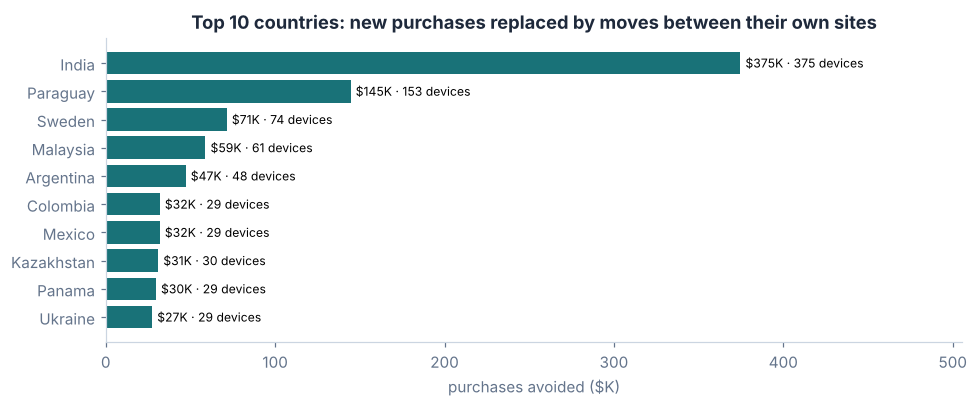

Largest single moves (within country):


device,from,to,devices,cost per device
Laptop,Sweden · site 06,Sweden · site 02,15,75.000000
Desktop,India · site 01,India · site 04,15,75.000000
Desktop,India · site 01,India · site 05,10,75.000000
Desktop,Ukraine · site 03,Ukraine · site 01,8,25.000000
Desktop,Sweden · site 02,Sweden · site 08,7,25.000000
Laptop,Panama · site 02,Panama · site 03,7,25.000000
Laptop,Argentina · site 01,Argentina · site 05,6,25.000000
Laptop,India · site 01,India · site 07,6,75.000000


In [ ]:
base, moves = scen["Within country (target)"]
by_country = (moves.assign(value=lambda m: m.devices * m.device.map(PRICE))
                   .groupby("to country").agg(devices=("devices", "sum"), purchases_avoided=("value", "sum"), sites_helped=("to", "nunique"))
                   .sort_values("purchases_avoided", ascending=False).head(10))
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.barh(by_country.index, by_country.purchases_avoided / 1e3, color=TEAL)
for i, (v, n) in enumerate(zip(by_country.purchases_avoided, by_country.devices)):
    ax.text(v / 1e3 + 3, i, f"${v / 1e3:,.0f}K · {n:,} devices", va="center", fontsize=8)
ax.invert_yaxis(); ax.set_xlabel("purchases avoided ($K)"); ax.set_xlim(0, by_country.purchases_avoided.max() / 1e3 * 1.35)
ax.set_title("Top 10 countries: new purchases replaced by moves between their own sites")
plt.tight_layout(); save(fig, "rebalancing by country"); plt.show()

print("Largest single moves (within country):")
moves.sort_values("devices", ascending=False).head(8)[["device", "from", "to", "devices", "cost per device"]].style.hide(axis="index")

## 6 · What the Excess Is Worth

After rebalancing, the useful stock that no site needs is **excess**. Devices past their lifecycle that are still on the shelf (**being decomm**) should be disposed of rather than counted as stock.

In [ ]:
s = scen["Within country (target)"][0]
excess = s["surplus left"]
excess_value = s["surplus value"].sum()
months_cover = excess.sum() / (g.backlog.sum() / BACKLOG_MONTHS + g.due_12m.sum() / 12 + g.in_use.sum() * BREAKFIX_RATE / 12)
decomm = g.decomm.sum()
print(f"Excess useful stock after rebalancing: {excess.sum():,.0f} devices, worth about {oc.money(excess_value)} at replacement price.")
print(f"That covers about {months_cover:.0f} months of total expected demand (refresh + backlog + break/fix) if purchases were paused.")
print(f"Stock past lifecycle (being decomm): {decomm:,.0f} devices to dispose or write off; reserved (last lifecycle year): {g.reserved.sum():,.0f}.")
ex = pd.DataFrame({"excess devices": excess, "value": s["surplus value"]})
ex["months of that type's demand"] = [excess[t] / max(1e-9, (g[g.asset_type == t].backlog.sum() / BACKLOG_MONTHS + g[g.asset_type == t].due_12m.sum() / 12
                                                           + g[g.asset_type == t].in_use.sum() * BREAKFIX_RATE / 12)) for t in ex.index]
ex.style.format({"excess devices": "{:,.0f}", "value": "${:,.0f}", "months of that type's demand": "{:.1f}"})

Excess useful stock after rebalancing: 9,867 devices, worth about $10.4M at replacement price.
That covers about 8 months of total expected demand (refresh + backlog + break/fix) if purchases were paused.
Stock past lifecycle (being decomm): 4,614 devices to dispose or write off; reserved (last lifecycle year): 977.


,excess devices,value,months of that type's demand
device,,,
Desktop,"1,493","$1,269,050",3.3
Handheld,0,$0,0.0
Laptop,"8,218","$9,039,800",12.9
Tablet,156,"$78,000",4.6


**Reading the excess**
* **9,867 useful devices (≈ USD 10.4M at replacement price) are not needed anywhere** after rebalancing. Most of them are laptops: 8,218, about **13 months of laptop demand**.
* The cheapest way to release that capital is to **pause new laptop orders** for sites with surplus and issue from stock until it reaches the target. Desktops (about 3 months of demand) and tablets (about 5) clear faster.
* **4,614 devices on the shelf are past their lifecycle** and 977 are in their last year. They should be disposed of or redeployed now: they count as stock in the 10% check but cannot be issued.

## 7 · What This Adds to the Dashboard

| Dashboard says | Notebook adds |
|---|---|
| Stock is far above 10% at many sites, below it at others | **What each site actually needs**, built from refresh dates, the overdue backlog and a measured 0.7% break/fix rate: about 2,800 devices in total. |
| One threshold for every site | **ABC–XYZ policies**: project-buy refresh waves at large sites, buffer stock at steady sites, hubs for the long tail. The square-root effect explains why a flat % fails. |
| Red/amber sites need action | A **rebalancing plan**: 1,024 devices to move within countries, about USD 0.95M net saving, and a list of moves. |
| — | **USD 10.4M of excess** and 4,614 decommission-ready devices on shelves, plus a policy that holds across 12 assumption scenarios. |

**Recommendations**
1. **Replace the flat 10% with a target per site and device type**, calculated as above, and show it in Power BI next to the actual stock.
2. **Run the rebalancing moves within countries first**, starting with India, Paraguay and Sweden.
3. **Pause laptop orders where surplus exists** until stock reaches the target. About 13 months of demand is already on shelves.
4. **Buy refresh waves as projects** timed to the lifecycle due date at large (A–Z) sites.
5. **Dispose of the 4,614 devices past their lifecycle**, and fix handheld availability: there is not one useful spare handheld in stock.

### Limitations
* **Demand is estimated, not observed.** The data is a snapshot, with no history of devices issued from stock. Refresh is inferred from the CI creation date and the lifecycle; break/fix from today's statuses.
* **Costs and lead time are assumptions.** The sensitivity table shows the direction holds across reasonable values; real freight quotes and supplier lead times would sharpen the numbers.
* **The model ignores constraints such as keyboard layouts, OS images and local procurement rules.** In practice, moves between countries with different languages or tax rules may not be allowed. That is why the default scenario stays within a country.
* Sites with unknown or unmapped countries are kept but cannot receive cross-border moves.